# EDA: Capturas por Delitos contra la Administración Pública - Policía Nacional (DIJIN)

**Objetivo:** Analizar los registros de capturas operativas de la Policía Nacional extraídos desde la API de Datos Abiertos (`datos.gov.co`, dataset `3jdh-nmwu`), enfocados en el **Título XV del Código Penal (Delitos contra la Administración Pública, Artículos 397 al 434)**, para identificar patrones territoriales, modalidades de corrupción y contratación estatal, y preparar los insumos de cruce con la Fiscalía, Procuraduría y Contraloría.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
print('¡Librerías cargadas correctamente!')

¡Librerías cargadas correctamente!


## Fase 1: Exploración de Datos Crudos (Capa Bronze)
Revisamos la estructura original descargada desde el endpoint `https://www.datos.gov.co/resource/3jdh-nmwu.csv`.

In [2]:
# Cargamos los datos crudos de la capa Bronze (3jdh-nmwu)
capturas_raw = pd.read_csv('../data/bronze/policia_capturas_raw.csv', dtype=str)
print(f'Dimensiones del dataset Bronze: {capturas_raw.shape}')
capturas_raw.head()

Dimensiones del dataset Bronze: (93031, 8)


,departamento,municipio,codigo_dane,fecha_hecho,genero,descripcion_conducta_captura,grupo_etario,cantidad
0,AMAZONAS,Leticia (CT),91001000,01/01/2010,MASCULINO,ARTÍCULO 429. VIOLENCIA CONTRA SERVIDOR PÚBLICO,ADULTOS,1
1,CALDAS,Manizales (CT),17001000,01/01/2010,MASCULINO,ARTÍCULO 429. VIOLENCIA CONTRA SERVIDOR PÚBLICO,ADULTOS,1
2,CALDAS,Manizales (CT),17001000,01/01/2010,MASCULINO,ARTÍCULO 429. VIOLENCIA CONTRA SERVIDOR PÚBLICO,ADULTOS,1
3,CALDAS,Manizales (CT),17001000,01/01/2010,MASCULINO,ARTÍCULO 429. VIOLENCIA CONTRA SERVIDOR PÚBLICO,ADULTOS,1
4,VALLE,Guadalajara de Buga,76111000,01/01/2010,MASCULINO,ARTÍCULO 429. VIOLENCIA CONTRA SERVIDOR PÚBLICO,ADULTOS,1


In [3]:
# Verificamos valores nulos y filas duplicadas en Bronze
print('Nulos por columna:\n', capturas_raw.isnull().sum())
print('\nFilas idénticas en Bronze:', capturas_raw.duplicated().sum())
print('Valores únicos por columna:\n', capturas_raw.nunique().sort_values())

Nulos por columna:
departamento                    0
municipio                       0
codigo_dane                     0
fecha_hecho                     0
genero                          0
descripcion_conducta_captura    0
grupo_etario                    0
cantidad                        0

Filas idénticas en Bronze: 22271
Valores únicos por columna:
cantidad                           1
genero                             2
grupo_etario                       3
departamento                      33
descripcion_conducta_captura      41
municipio                        976
codigo_dane                     1394
fecha_hecho                     6053


## Fase 2: Datos Estandarizados y Clasificados (Capa Silver)
En la capa Silver se eliminaron duplicados, se normalizaron los nombres de departamentos y municipios sin tildes, se estandarizó `cod_dane_hecho` a 5 dígitos municipales, se extrajo el `articulo` del Código Penal y se clasificó cada conducta en los 11 capítulos del Título XV, separando **Contra Servidores Públicos (Arts. 429-430)** de **Corrupción y Función Pública (Arts. 397-428 y 431-434)**.

In [4]:
capturas = pd.read_csv('../data/silver/policia_capturas_clean.csv', dtype={'cod_dane_hecho': str, 'articulo': str})
print(f'Dimensiones en Silver: {capturas.shape}')
print('\nDistribución por categoría del delito:')
print(capturas.groupby('categoria_delito')['cantidad'].sum())
capturas.head()

Dimensiones en Silver: (70685, 14)

Distribución por categoría del delito:
categoria_delito
Contra Servidores Publicos      56340
Corrupcion Y Funcion Publica    14345


,departamento_hecho,municipio_hecho,fecha_hecho,genero,grupo_etario,cantidad,cod_dane_hecho,año_hecho,mes_hecho,articulo,delito,capitulo_delito,titulo_delito,categoria_delito
0,AMAZONAS,LETICIA,2010-01-01,MASCULINO,ADULTOS,1,91001,2010,1,429,VIOLENCIA CONTRA SERVIDOR PUBLICO,De Los Delitos Contra Los Servidores Publicos,Delitos Contra La Administracion Publica,Contra Servidores Publicos
1,CALDAS,MANIZALES,2010-01-01,MASCULINO,ADULTOS,1,17001,2010,1,429,VIOLENCIA CONTRA SERVIDOR PUBLICO,De Los Delitos Contra Los Servidores Publicos,Delitos Contra La Administracion Publica,Contra Servidores Publicos
2,VALLE DEL CAUCA,GUADALAJARA DE BUGA,2010-01-01,MASCULINO,ADULTOS,1,76111,2010,1,429,VIOLENCIA CONTRA SERVIDOR PUBLICO,De Los Delitos Contra Los Servidores Publicos,Delitos Contra La Administracion Publica,Contra Servidores Publicos
3,VALLE DEL CAUCA,TULUA,2010-01-01,FEMENINO,ADULTOS,1,76834,2010,1,429,VIOLENCIA CONTRA SERVIDOR PUBLICO,De Los Delitos Contra Los Servidores Publicos,Delitos Contra La Administracion Publica,Contra Servidores Publicos
4,SUCRE,GALERAS,2010-01-01,MASCULINO,ADULTOS,1,70235,2010,1,429,VIOLENCIA CONTRA SERVIDOR PUBLICO,De Los Delitos Contra Los Servidores Publicos,Delitos Contra La Administracion Publica,Contra Servidores Publicos


## Fase 3: Análisis de Modalidades de Corrupción y Contratación Pública (Capa Gold)
Aislamos el bloque de **Corrupción y Función Pública** (excluyendo el ruido operativo de violencia contra servidor público del Art. 429) para examinar los capítulos del Código Penal con más capturas.

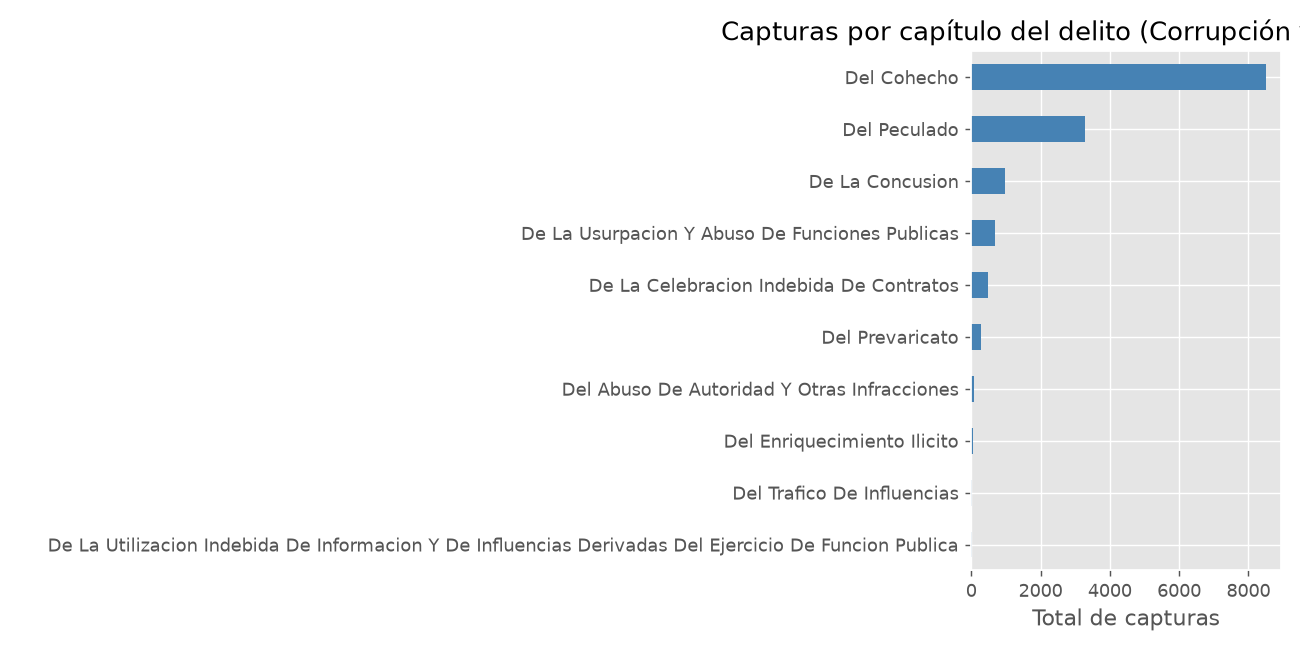

In [5]:
corrupcion = capturas[capturas['categoria_delito'] == 'Corrupcion Y Funcion Publica']
por_capitulo = corrupcion.groupby('capitulo_delito')['cantidad'].sum().sort_values()
por_capitulo.plot(kind='barh', figsize=(10, 5), color='steelblue')
plt.title('Capturas por capítulo del delito (Corrupción y Función Pública)')
plt.xlabel('Total de capturas')
plt.ylabel('')
plt.show()

,articulo,delito,capitulo_delito,total_capturas,porcentaje
0,407,COHECHO POR DAR U OFRECER,Del Cohecho,8059,11.40
1,397,PECULADO POR APROPIACION,Del Peculado,2067,2.92
2,404,CONCUSION,De La Concusion,987,1.40
3,402,OMISION DEL AGENTE RETENEDOR O RECAUDADOR,Del Peculado,913,1.29
4,426,SIMULACION DE INVESTIDURA O CARGO,De La Usurpacion Y Abuso De Funciones Publicas,570,0.81
5,405,COHECHO PROPIO,Del Cohecho,382,0.54
6,410,CONTRATO SIN CUMPLIMIENTO DE REQUISITO LEGALES,De La Celebracion Indebida De Contratos,294,0.42
7,413,PREVARICATO POR ACCION,Del Prevaricato,156,0.22
8,409,INTERES INDEBIDO EN LA CELEBRACION DE CONTRATOS,De La Celebracion Indebida De Contratos,139,0.20
9,398,PECULADO POR USO,Del Peculado,122,0.17


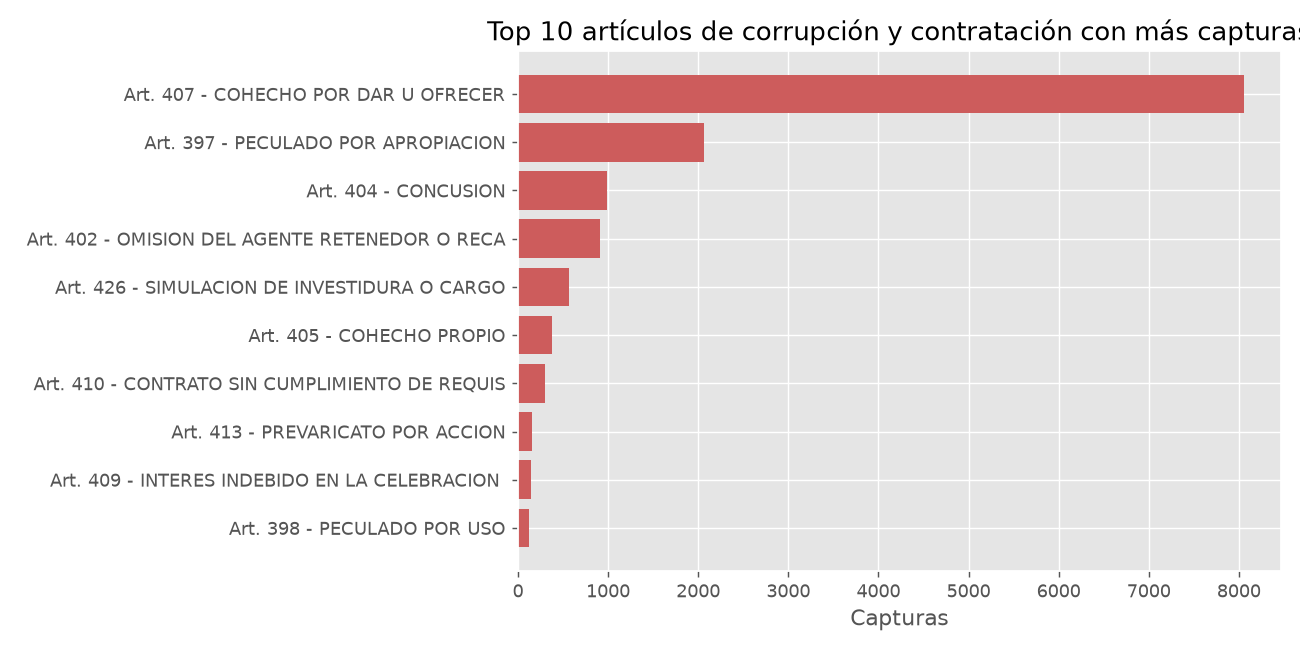

In [6]:
# Top 10 artículos de corrupción y contratación pública con más capturas
top_delitos = pd.read_csv('../data/gold/policia_top_delitos_gold.csv')
top_corr = top_delitos[top_delitos['categoria_delito'] == 'Corrupcion Y Funcion Publica'].head(10)
top_corr[['articulo', 'delito', 'capitulo_delito', 'total_capturas', 'porcentaje']]

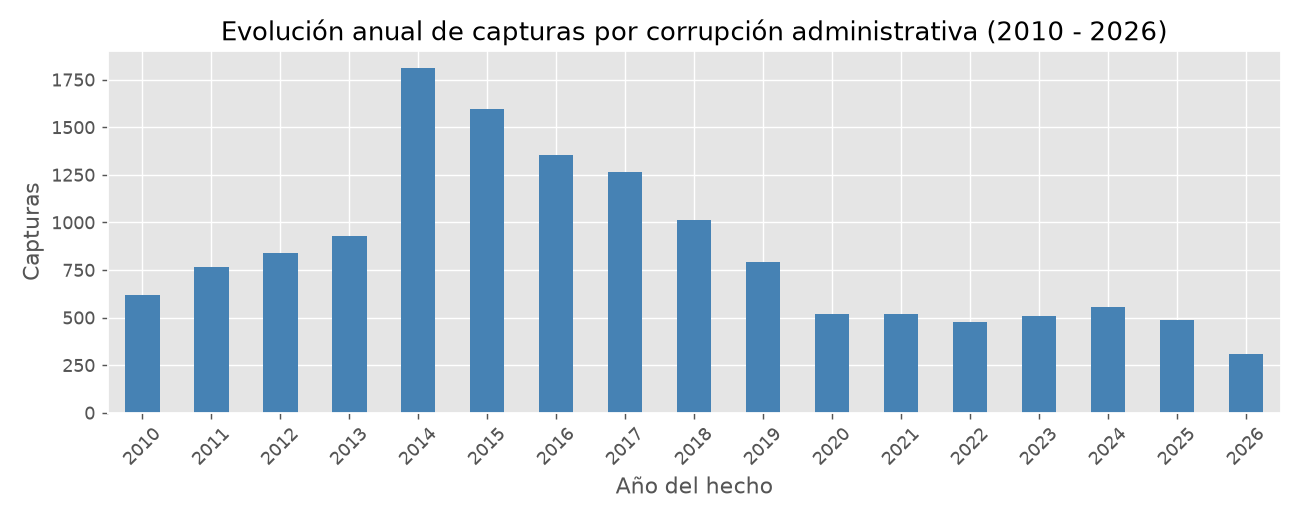

In [7]:
# Evolución anual de capturas por delitos de corrupción
por_año = corrupcion.groupby('año_hecho')['cantidad'].sum().sort_index()
por_año.plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Evolución anual de capturas por corrupción administrativa (2010 - 2026)')
plt.xlabel('Año del hecho')
plt.ylabel('Capturas')
plt.xticks(rotation=45)
plt.show()

,departamento_hecho,total_capturas,capturas_corrupcion,pct_corrupcion,pct_nacional
0,"BOGOTA, D. C.",8919,2553,28.62,12.62
1,ANTIOQUIA,10164,1625,15.99,14.38
2,CUNDINAMARCA,3975,1426,35.87,5.62
3,NARINO,3408,932,27.35,4.82
4,VALLE DEL CAUCA,5340,909,17.02,7.55
5,ATLANTICO,2650,721,27.21,3.75
6,SUCRE,1506,701,46.55,2.13
7,MAGDALENA,1721,618,35.91,2.43
8,BOLIVAR,2597,535,20.60,3.67
9,SANTANDER,5085,493,9.70,7.19


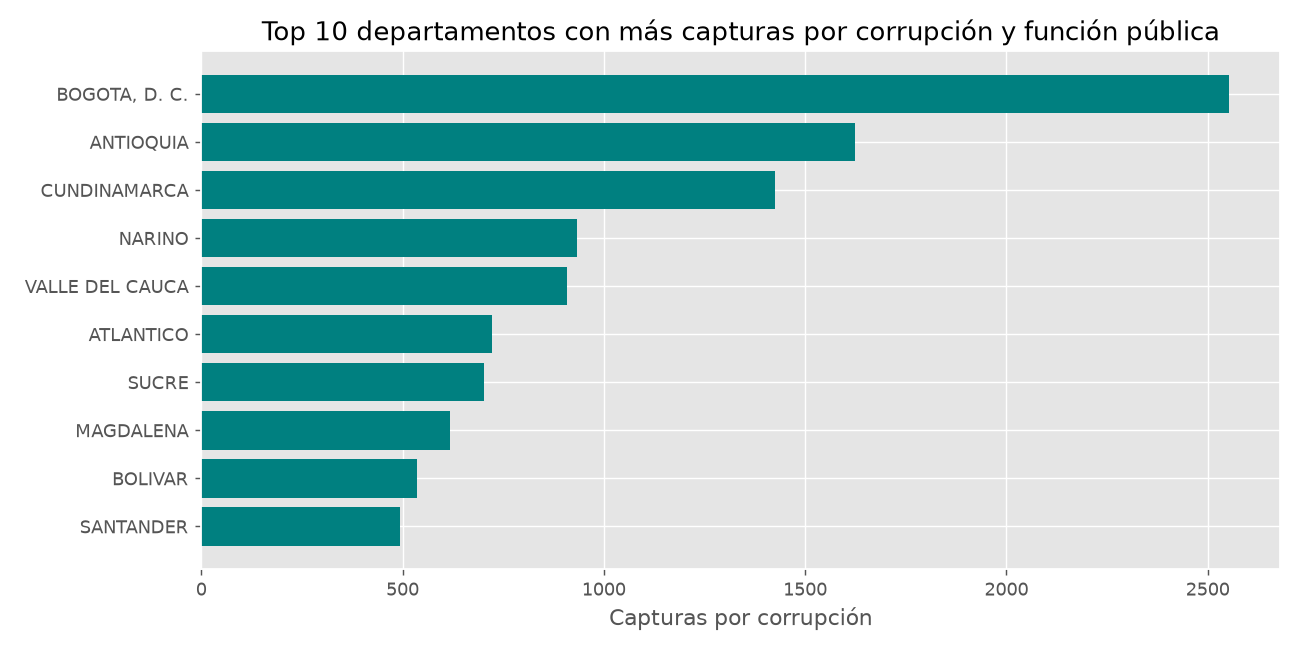

In [8]:
# Departamentos con mayor volumen de capturas por corrupción administrativa
depto_gold = pd.read_csv('../data/gold/policia_capturas_departamento_gold.csv')
top_deptos_corr = depto_gold.sort_values('capturas_corrupcion', ascending=False).head(10)
top_deptos_corr

In [9]:
# Detalle específico: Capturas por Celebración Indebida de Contratos (Arts. 408 al 410A)
contratos = capturas[capturas['capitulo_delito'] == 'De La Celebracion Indebida De Contratos']
pd.crosstab(contratos['delito'], contratos['genero'], values=contratos['cantidad'], aggfunc='sum', margins=True)

genero,FEMENINO,MASCULINO,All
delito,,,
ACUERDOS RESTRICTIVOS DE LA COMPETENCIA,NaN,3.0,3
CONTRATO SIN CUMPLIMIENTO DE REQUISITO LEGALES,47.0,247.0,294
INTERES INDEBIDO EN LA CELEBRACION DE CONTRATOS,23.0,116.0,139
VIOLACION DEL REGIMEN LEGAL O CONSTITUCIONAL DE INHABILIDADES E INCOMPATIBILIDADES,6.0,33.0,39
All,76.0,399.0,475
